# QOBLIB / 08 - Network Traffic Optimization

Given an $n × n$ demand matrix $T = (t_{ij})$ (where  $t_{ij}$ represents traffic from node $i$ to node $j$) and an integer $p > 0$:

1. Construct a simple directed graph $D$ with node set $\{1,…,n\}$ where each node has in-degree and out-degree equal to $p$
2. Route $t_{ij}$ defines traffic flow from $i$ to $j$ for all $1 ≤ i,j ≤ n$ with $i ≠ j$
3. Minimize the maximum aggregate flow on any edge of $D$

Instance Parameters:
+ $p = 2$ (each node has 2 incoming and 2 outgoing connections)
+ $n∈\{5,…,24\}$ nodes
+ Demand matrix entries: $t_{ij} ∈{0}∪[16,100]$

Which one-way links should we build to carry all the requested traffic? Every node needs exactly **two incoming and two outgoing links**. Traffic may split across paths. The score represents the **load on the busiest link**, so lower is better.

This notebook presents an approach to solving this problem using a hybrid quantum-classical pipeline, together with _ShinkaEvolve_ in order to genetically find the optimal parameters to build the _QUBO_ matrix and to further optimise the resultant graph classically.

In [14]:
import json
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from IPython.display import Markdown, display

import qoblib_tools as qt
from experiments.workflow import RECIPES, candidate_pool, run_search

## Choose a run

Select a QAOA-seeded run from `network11` through `network24`. Archived mode uses the recorded candidate pool and runs the original classical search on your machine. Some searches have a time limit, so their final score can depend on machine speed. Section 5 also checks the classical-only submission for `network10`.

Set `FRESH_QAOA = True` to generate new candidates. Choose `local` or `cloud` for the backend. Cloud sampling uses your `QORO_API_KEY` from the environment or the repository-root `.env` file. [Qoro cloud setup](https://docs.qoroquantum.net/divi/cloud_sim/)

In [15]:
REPLAY = "network11"
FRESH_QAOA = False
QAOA_BACKEND = "cloud"

In [16]:
DATA = Path.cwd() / "data"
if not (DATA / "demand.csv").is_file():
    raise RuntimeError("Open this notebook from the repository root.")

if REPLAY not in RECIPES:
    raise ValueError(f"Choose one of {', '.join(RECIPES)}")
recipe = RECIPES[REPLAY]
size = int(REPLAY.removeprefix("network"))

def table(headers, rows):
    lines = [headers, ["---"] * len(headers), *rows]
    display(Markdown("\n".join("| " + " | ".join(map(str, row)) + " |" for row in lines)))

## 1 Demand Matrix

The following shows the demand matrix, denoting how much traffic nodes want to send to other nodes. This is given by QOBLIB from GitHub and reaches up to 24 nodes. However, the amount of nodes may be adjusted down to 5 nodes, below which the two ingress and egress edge constraint breaks. In this notebook, you may run simulations from 11 nodes up to 24.

The full 24-node demand matrix is stored in [data/demand.csv](data/demand.csv). Each instance uses the first rows and columns up to its node count.

In [17]:
NETWORK_DEMAND = np.loadtxt(DATA / "demand.csv", delimiter=",", dtype=np.int64)

def load_network_demand(size):
    """Return the demand between the first size nodes of the benchmark."""
    if not 5 <= size <= len(NETWORK_DEMAND):
        raise ValueError("Choose a network size between 5 and 24.")
    return NETWORK_DEMAND[:size, :size].copy()

demand_matrix = load_network_demand(size)

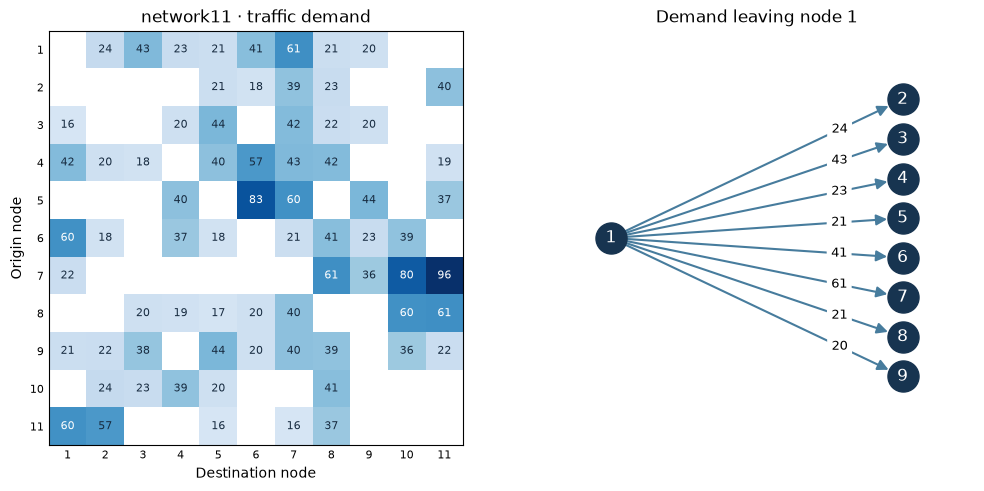

In [18]:
node_ids = np.arange(1, len(demand_matrix) + 1)
fig, (matrix_ax, graph_ax) = plt.subplots(
    1, 2, figsize=(max(10, len(node_ids) * 0.65), max(4.8, len(node_ids) * 0.38)),
    gridspec_kw={"width_ratios": [1.25, 1]}, layout="constrained")

# Display every positive origin–destination pair in QOBLIB's one-based node numbering.
matrix_ax.imshow(np.ma.masked_equal(demand_matrix, 0), cmap="Blues", vmin=0, vmax=demand_matrix.max())
for i, j in zip(*np.nonzero(demand_matrix)):
    amount = demand_matrix[i, j]
    matrix_ax.text(j, i, str(amount), ha="center", va="center",
                   fontsize=8, color="white" if amount > 0.62 * demand_matrix.max() else "#172b40")
matrix_ax.set(xticks=node_ids - 1, xticklabels=node_ids, yticks=node_ids - 1, yticklabels=node_ids,
              xlabel="Destination node", ylabel="Origin node", title=f"{REPLAY} · traffic demand")
matrix_ax.tick_params(length=0, labelsize=8)

# Unfold row 1 as a directed graph so the direction and units are explicit.
graph = nx.DiGraph()
graph.add_node(1)
graph.add_weighted_edges_from((1, int(j + 1), int(demand_matrix[0, j]))
                              for j in np.flatnonzero(demand_matrix[0]))
destinations = list(graph.successors(1))
positions = {1: (0, 0)}
positions.update({node: (1, y) for node, y in zip(destinations, np.linspace(1, -1, len(destinations)))})
nx.draw_networkx(graph, positions, ax=graph_ax, node_size=500, node_color="#173450",
                 font_color="white", edge_color="#477c9d", arrowsize=16, width=1.5)
nx.draw_networkx_edge_labels(graph, positions, ax=graph_ax,
                             edge_labels=nx.get_edge_attributes(graph, "weight"),
                             label_pos=0.8, rotate=False, font_size=9)
graph_ax.set_title("Demand leaving node 1")
graph_ax.margins(0.18)
graph_ax.set_axis_off()
plt.show()

## 2 Quantum Optimization with QAOA through QUBO

The below table shows the optimal functions made by _ShinkaEvolve_ for different the different network sizes in this problem. The selected QUBO builder rewards promising links and two-hop routes. Degree penalties favor designs with two incoming and two outgoing links per node. In a fresh run, Divi splits the QUBO into blocks, samples them with QAOA, and combines the samples into candidate networks.

Each row identifies the QAOA pool, its builder, the classical search program, and the maximum number of routing evaluations used for that instance.

In [19]:
table(["Instance", "QUBO builder", "Starting pool", "Classical search", "LP budget"],
      [[name, run.builder, run.pool, run.search_name, f"{run.budget:,}"] for name, run in RECIPES.items()])

| Instance | QUBO builder | Starting pool | Classical search | LP budget |
| --- | --- | --- | --- | --- |
| network11 | r3g128 | network11_r3g128_c16p2loc_seed0 | init_run1_gen49 | 10,000 |
| network12 | r3g128 | network12_r3g128_c20p2_seed0 | init_run1_gen49 | 10,000 |
| network13 | r3g128 | network13_r3g128_seed0 | init_run1_gen49 | 20,000 |
| network14 | r3g128 | network14_r3g128_seed1 | harvest_A_gen20 | 20,000 |
| network15 | r3g128 | network15_r3g128_seed0 | ckpt_A_gen20 | 10,000 |
| network16 | r2g181 | network16_r2g181_seed1 | harvest_A_gen20 | 20,000 |
| network17 | r2g181 | network17_r2g181_seed1 | harvest_A_gen33 | 25,000 |
| network18 | r3g128 | network18_r3g128_seed1 | ckpt_A_gen20 | 10,000 |
| network19 | r2g181 | network19_r2g181_seed1 | harvest_A_gen33 | 25,000 |
| network20 | r3g128 | network20_r3g128_seed1 | harvest_A_gen20 | 20,000 |
| network21 | r3g128 | network21_r3g128_c16p2loc_seed0 | init_run1_gen49 | 10,000 |
| network22 | r3g128 | network22_r3g128_seed0 | harvest_A_gen20 | 20,000 |
| network23 | r2g181 | network23_r2g181_seed0 | harvest_A_gen20 | 20,000 |
| network24 | r3g128 | network24_r3g128_seed0 | harvest_A_gen20 | 25,000 |

### Sample or load the starting pool

The output reports how many **circuits** produced how many **candidate networks**. The candidate count is `len(starts)`, the size of the pool passed to Section 3. **First repaired candidate** scores one example from this pool.

In [20]:
starts, circuits = candidate_pool(demand_matrix, recipe, DATA / "pools", FRESH_QAOA, QAOA_BACKEND)
mode = f"Fresh {QAOA_BACKEND}" if FRESH_QAOA else "Archived"
print(f"{REPLAY} · {recipe.builder} · {mode} QAOA: {circuits:,} circuits, {len(starts)} candidates.")
first = qt.repair_topology(size, starts[0], demand_matrix)
print(f"First repaired candidate: {qt.route_min_congestion(demand_matrix, first).objective:,.0f}")

network11 · r3g128 · Archived QAOA: 5,511 circuits, 200 candidates.
First repaired candidate: 262,200


## 3 Further Classical Optimization

The selected _ShinkaEvolve_ program repairs candidates, tests link swaps, and keeps the network with the lowest verified peak load. The routing oracle scores each distinct topology and tracks the LP budget. The original gen20 checkpoint used for networks 15 and 18 also stops after about 140 seconds.

In [21]:
score, links, calls = run_search(demand_matrix, starts, recipe)
print(f"{REPLAY} · {recipe.search_name}: {calls:,} LP calls, best routing score {score:,.0f}")

network11 · init_run1_gen49: 10,000 LP calls, best routing score 238,334


### Verify the winner against its integer flows

The next cell routes integer flows on the winning links and checks the generated solution with `qoblib_tools`. The LP score is a lower bound. The verified integer-flow score is the peak shown on the final graph.

In [22]:
routing = qt.route_integral(demand_matrix, links)
reference_path = DATA / "solutions" / f"network{size:02d}.sol"
with TemporaryDirectory() as folder:
    generated = Path(folder) / f"network{size:02d}.sol"
    qt.write_network_solution(generated, size, routing)
    valid, generated_score, reason = qt.check_network_solution(generated, size, demand_matrix)
assert valid and score <= generated_score == routing.objective, (reason, generated_score, score)
reference_valid, reference_score, _ = qt.check_network_solution(reference_path, size, demand_matrix)
assert reference_valid
records = json.loads((DATA / "records.json").read_text())
table(["Instance", "LP score", "Verified integer flow", "Recorded QAOA winner", "Best archived submission"],
      [[REPLAY, f"{score:,.0f}", f"{generated_score:,}", f"{records['quantum'][REPLAY]['score']:,.0f}",
        f"{reference_score:,}"]])

| Instance | LP score | Verified integer flow | Recorded QAOA winner | Best archived submission |
| --- | --- | --- | --- | --- |
| network11 | 238,334 | 238,334 | 238,334 | 238,334 |

## 4 Display the Winning Network

Each arrow shows a selected link. Its label gives the total traffic routed along it in demand units, and thicker arrows carry more traffic. Red arrows reach the peak load, which equals the verified score divided by 1,000.

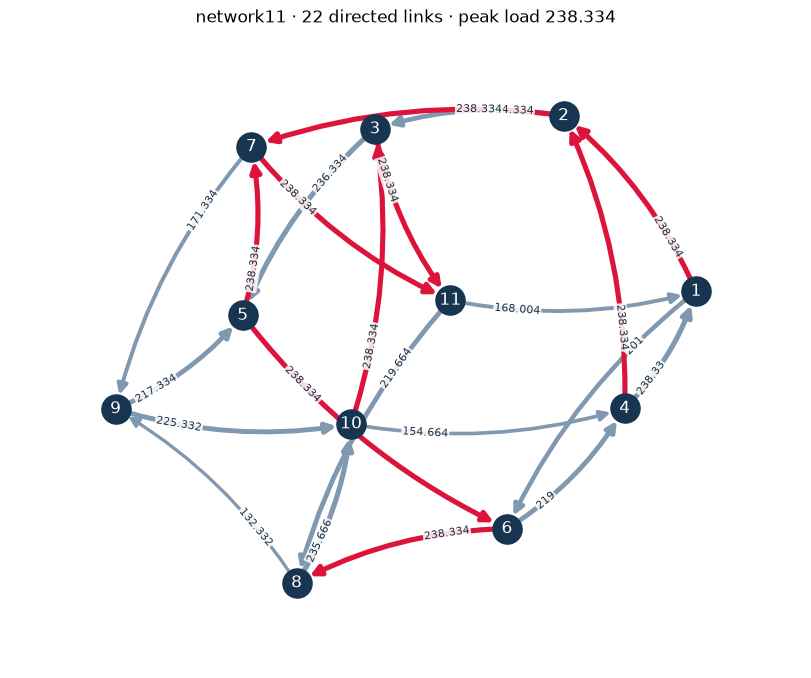

In [23]:
solution_graph = nx.DiGraph()
solution_graph.add_edges_from(routing.arcs, weight=0)
for (_, origin, destination), flow in routing.flows.items():
    solution_graph[origin][destination]["weight"] += flow

weights = nx.get_edge_attributes(solution_graph, "weight")
peak = max(weights.values())
assert peak == routing.objective
edges = sorted(weights, key=weights.get)
positions = nx.kamada_kawai_layout(solution_graph.to_undirected(), weight=None,
                                   pos=nx.circular_layout(sorted(solution_graph)))
side = max(8, len(solution_graph) / 2)
fig, ax = plt.subplots(figsize=(side, side), layout="constrained")
nx.draw_networkx(solution_graph, positions, ax=ax, edgelist=edges,
                 labels={node: node + 1 for node in solution_graph},
                 node_color="#173450", node_size=440, font_color="white",
                 edge_color=["#DC143C" if weights[e] == peak else "#8099b0" for e in edges],
                 width=[0.7 + 3 * weights[e] / max(peak, 1) for e in edges],
                 arrowsize=15, connectionstyle="arc3,rad=0.12")
nx.draw_networkx_edge_labels(
    solution_graph, positions, ax=ax, node_size=440, connectionstyle="arc3,rad=0.12",
    edge_labels={e: f"{load / qt.INTSCALE:.3f}".rstrip("0").rstrip(".") for e, load in weights.items()},
    label_pos=0.25, font_size=8, font_color="#253647",
    bbox=dict(boxstyle="round,pad=0.1", facecolor="white", edgecolor="none", alpha=0.85),
)
ax.set_title(f"{REPLAY} · {len(edges)} directed links · peak load {peak / qt.INTSCALE:,.3f}")
ax.margins(0.12)
ax.set_aspect("equal")
ax.set_axis_off()
plt.show()

## 5 Verify the archived submissions

This cell checks the 15 solution files submitted during the hackathon. For each file it verifies the integer flows, recomputes the routing score, and compares the score with the benchmark used in the pitch. A negative gap means the submission improved on that benchmark.

In [24]:
result_rows = []
gaps = []
for archive_size in range(10, 25):
    name = f"network{archive_size:02d}"
    record = records["overall"][name]
    path = DATA / "solutions" / f"{name}.sol"
    archive_demand = load_network_demand(archive_size)
    valid, checked, reason = qt.check_network_solution(path, archive_size, archive_demand)
    claimed, archived_links, _ = qt.read_network_solution(path)
    lp_score = qt.route_min_congestion(archive_demand, archived_links).objective
    assert valid and claimed == checked == lp_score == record["score"], (name, reason, checked, lp_score)
    gap = 100 * (checked / record["bkv"] - 1)
    gaps.append(gap)
    qaoa_match = records["quantum"].get(name, {}).get("score") == checked
    result_rows.append([name, f"{record['bkv']:,}", f"{checked:,}", f"{gap:+.2f}%",
                        "Yes" if qaoa_match else "No"])
table(["Instance", "Benchmark", "Verified score", "Gap", "QAOA-seeded run attained score?"], result_rows)
print(f"{sum(g < 0 for g in gaps)} improvements and {gaps.count(0)} ties.")

| Instance | Benchmark | Verified score | Gap | QAOA-seeded run attained score? |
| --- | --- | --- | --- | --- |
| network10 | 210,800 | 210,800 | +0.00% | No |
| network11 | 238,334 | 238,334 | +0.00% | Yes |
| network12 | 276,474 | 276,474 | +0.00% | No |
| network13 | 300,620 | 299,715 | -0.30% | Yes |
| network14 | 343,091 | 341,375 | -0.50% | Yes |
| network15 | 370,870 | 369,720 | -0.31% | Yes |
| network16 | 397,908 | 395,566 | -0.59% | Yes |
| network17 | 437,000 | 431,938 | -1.16% | Yes |
| network18 | 473,375 | 466,000 | -1.56% | Yes |
| network19 | 492,924 | 480,000 | -2.62% | Yes |
| network20 | 528,528 | 511,769 | -3.17% | Yes |
| network21 | 569,273 | 557,053 | -2.15% | Yes |
| network22 | 618,135 | 597,524 | -3.33% | Yes |
| network23 | 659,369 | 636,848 | -3.42% | Yes |
| network24 | 663,688 | 659,539 | -0.63% | Yes |

12 improvements and 3 ties.


The strongest improvement was **3.42% on network23**. On network24, peak load fell from **663,688 to 659,539** checker units.